# A4 — Ley de los Grandes Números

## Objetivos
- Comprender la diferencia entre parámetro y estimador.
- Calcular una media muestral.
- Simular observaciones aleatorias.
- Analizar la convergencia de la media.
- Visualizar los resultados con Python.

### Contexto práctico
Analizaremos tiempos de permanencia de usuarios
en una plataforma digital.


In [3]:
import numpy as np
tiempos= np.array ([8,12,15,17,23])
media= np.mean (tiempos)

print("Media muestral:", media)


Media muestral: 15.0


In [8]:
rng = np.random.default_rng(42)

#generar una muestra de 100 usuario
muestra = rng.normal(
    loc=15,
    scale=3,
    size=1000
)
#calcular su media
media_simulada = np.mean(muestra)

#mostrar los resultado
print ("cantidad de usuario:", len (muestra))
print ("media simulada:", media_simulada)

cantidad de usuario: 1000
media simulada: 14.91332534701216


In [9]:
import numpy as np

notas = np.array([3, 4, 4, 4, 5])

media = np.mean(notas)

desviacion = np.std(notas, ddof=1)

print("Media:", media)
print("Desviación estándar:", desviacion)

Media: 4.0
Desviación estándar: 0.7071067811865476


In [10]:
import numpy as np

notas = np.array([10.5,10.5,10.5,10.5,10.5])

media = np.mean(notas)

desviacion = np.std(notas, ddof=1)

print("Media:", media)
print("Desviación estándar:", desviacion)

Media: 10.5
Desviación estándar: 0.0


In [12]:
import numpy as np

rng = np.random.default_rng(42)

# Simulamos 10.000 usuarios
muestra_grande = rng.normal(
    loc=15,    
    scale=3,
    size=10_000
)

In [13]:
sumas = np.cumsum(muestra_grande)

cantidad = np.arange(1, len(muestra_grande) + 1)

promedios = sumas / cantidad


print("Promedio final:", promedios[-1])

Promedio final: 14.969250373757943


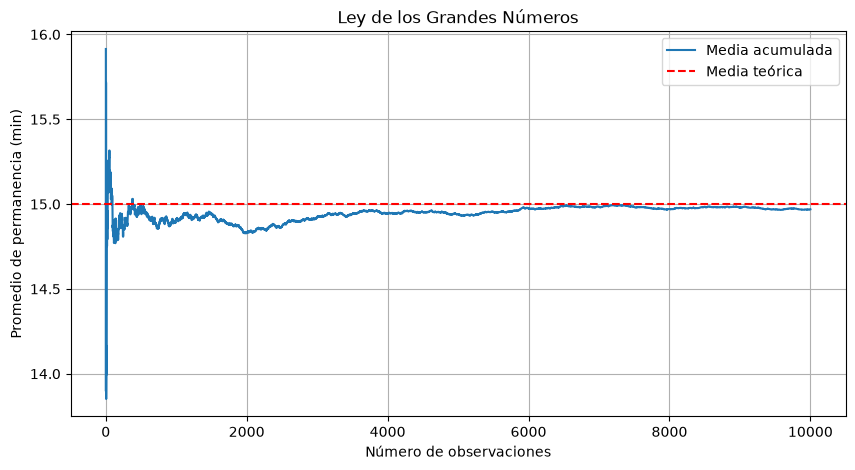

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(cantidad, promedios, label="Media acumulada")

plt.axhline(
    y=15,
    color="red",
    linestyle="--",
    label="Media teórica"
)

plt.xlabel("Número de observaciones")
plt.ylabel("Promedio de permanencia (min)")
plt.title("Ley de los Grandes Números")
plt.legend()
plt.grid(True)

plt.show()

**introducción al método Monte Carlo**
1. ¿Qué es Monte Carlo?
Monte Carlo es un conjunto de métodos computacionales que utilizan simulaciones aleatorias repetidas para estimar probabilidades, resultados esperados o comportamientos de sistemas.



In [15]:
import numpy as np

temperaturas = np.array([82, 94, 76, 92, 85])

# Variable indicadora: True si supera 90 °C
indicador = temperaturas > 90

# Sumatoria de los eventos
eventos = np.sum(indicador)

# Número total de simulaciones
N = len(temperaturas)

# Probabilidad estimada
p_estimada = eventos / N

print(f"Probabilidad estimada: {p_estimada:.0%}")

Probabilidad estimada: 40%


In [16]:
import numpy as np

rng = np.random.default_rng(42)

temperaturas = rng.normal(
    loc=75,
    scale=8,
    size=10_000
)

print("Primeras temperaturas:", temperaturas[:5])
print("Total de simulaciones:", len(temperaturas))

Primeras temperaturas: [77.43773664 66.68012715 81.00360957 82.52451773 59.39171849]
Total de simulaciones: 10000


In [19]:
limite_critico = 90

sobrecalentamientos = temperaturas > limite_critico

print("Primeros resultados:", sobrecalentamientos[:450])

Primeros resultados: [False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False  True False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False  True  True False False False False
 False False False False False False False False False False False False
 False False False False False

In [21]:
cantidad_fallas = np.sum(sobrecalentamientos)

probabilidad = np.mean(sobrecalentamientos)

print("Sobrecalentamientos:", cantidad_fallas)
print(f"Probabilidad estimada: {probabilidad:.2%}")



Sobrecalentamientos: 308
Probabilidad estimada: 3.08%


In [22]:
eventos_acumulados = np.cumsum(sobrecalentamientos)

print(eventos_acumulados[:10])


[0 0 0 0 0 0 0 0 0 0]


In [23]:
n = np.arange(1, len(sobrecalentamientos) + 1)

probabilidades_acumuladas = eventos_acumulados / n

print(probabilidades_acumuladas[:10])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


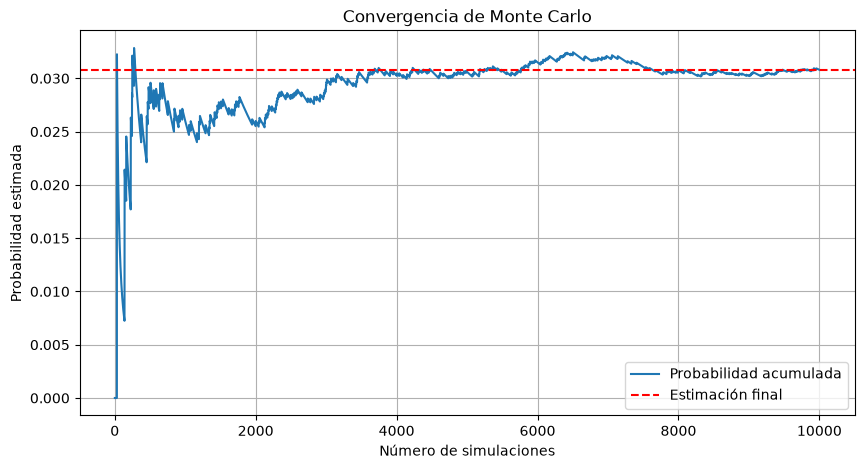

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    n,
    probabilidades_acumuladas,
    label="Probabilidad acumulada"
)

plt.axhline(
    y=probabilidad,
    color="red",
    linestyle="--",
    label="Estimación final"
)

plt.xlabel("Número de simulaciones")
plt.ylabel("Probabilidad estimada")
plt.title("Convergencia de Monte Carlo")
plt.legend()
plt.grid(True)

plt.show()


**3. Ejercicio guiado en Python — Estimar el costo esperado**

Continuaremos en A5_Introduccion_MonteCarlo.ipynb, creando una sección nueva titulada A6 — Estimación mediante Monte Carlo.
Usaremos las 10.000 temperaturas que simulamos anteriormente, sin volver a generarlas.

In [29]:
costo_falla = 200_000

costos = np.where(
    temperaturas > 90,
    costo_falla,
    0
)

print("Primeros 10 costos:", costos[:10])


Primeros 10 costos: [0 0 0 0 0 0 0 0 0 0]


In [30]:
costo_promedio = np.mean(costos)

print(f"Costo promedio estimado: ${costo_promedio:,.0f}")




Costo promedio estimado: $6,160


In [31]:
costo_alternativo = probabilidad * costo_falla

print("Promedio Monte Carlo:", costo_promedio)
print("Cálculo alternativo:", costo_alternativo)



Promedio Monte Carlo: 6160.0
Cálculo alternativo: 6160.0


In [32]:
desviacion_costos = np.std(costos, ddof=1)

error_montecarlo = desviacion_costos / np.sqrt(len(costos))

print(f"Error estándar Monte Carlo: ${error_montecarlo:,.2f}")


Error estándar Monte Carlo: $345.57
